# Does cache contamination limit Ramen? An oracle upper bound

**Question.** Ramen stores every test image in a memory (cache) and adapts the model on images retrieved from it. Images the zero-shot model gets *wrong* — especially *confidently* wrong — sit in the memory filed under the wrong class. Is that contamination what holds Ramen back? If we could remove it perfectly, how much accuracy would we gain?

**Why an oracle.** Before designing a real contamination detector (weeks of work), we measure the most any detector could gain: we let the method *cheat* and use the true labels to hide contaminated entries. If even a perfect detector gains little, the direction is not worth pursuing. If it gains a lot, the project becomes "find a label-free signal that matches the oracle".

**How contamination enters Ramen** (`src/methods/Ramen.py`). Every image is written, before retrieval, into the queue of its zero-shot prediction, together with its own entropy-minimisation gradient and its entropy H. Retrieval takes the nearest entries from every class queue and weights each by exp(−H)·exp(−β·d). A confidently wrong image has low H, so it gets close to the largest weight there is, and its gradient pushes towards its own wrong class.

**Hypothesis.** Hiding confidently wrong entries raises accuracy over Ramen by more than the noise floor, and by more than hiding the same number of entries at random.

### Variants (`src/methods/RamenOracle.py`, config `cfg/<dataset>/RamenOracle.yaml`)

| Run name | What it changes | Uses true labels? |
|---|---|---|
| `oracle_none` | nothing — must equal Ramen exactly (sanity check) | no |
| `oracle_file_true` | each image is filed under its **true** class, so every queue is 100% pure (its stored gradient is unchanged) | yes |
| `oracle_drop_wrong` | entries whose zero-shot prediction was wrong are never retrieved; each queue returns its nearest correct entries instead | yes |
| `oracle_random_like_wrong` | **control**: hide entries at random, at the running zero-shot error rate (about as many as `drop_wrong`) | rate only |
| `oracle_drop_cw` | hide only entries that are wrong **and** confident (entropy below the running median of all images seen so far) | yes |
| `oracle_random_like_cw` | **control**: hide at random, at the running confident-wrong rate | rate only |

Hidden entries still occupy memory slots and are evicted by Ramen's normal rule; only retrieval skips them. Every decision is made when the image is written, using only images seen so far (causal).

### Data, models, seeds

| | ImageNet-C 5K | DomainNet |
|---|---|---|
| Images | 75,000 = 15 corruptions × 5,000 (severity 5) | 596,006 over 6 domains |
| Classes | 1,000 | 345 |
| Model | CLIP ViT-B/16 | CLIP ViT-B/32 |
| Ramen config | queue capacity 75, top-1 per queue, β = 0 | capacity 300, top-10 per queue, β = 5 |
| Stream | mixed: all domains shuffled into one stream, batches of 100 | same |
| Noise floor | 0.54 points | 0.11 points |

**Seeds.** A seed fixes the order of the shuffled stream; the random draws of the `random_like_*` controls use their own generator (`oracle_seed: 0`), so they differ across seeds only through the stream. The zero-shot model (NoAdapt) gives the same predictions for every seed. All six variants ran on **seed 0** (screening, sections 2–5). The one variant that cleared the noise floor (hide confident-wrong, on DomainNet) and its random control were then re-run on **seeds 1–4**, on both datasets (section 4b, `run_seed_sweep.sh`).

**What counts as a result.** A gain over Ramen larger than the noise floor = 2 × (max − min) of Ramen's accuracy over seeds 0–4. An oracle must also beat its own random control; otherwise the gain comes from hiding entries at all, not from hiding the *wrong* ones.

**How the runs were produced.** `run_oracles.py` in this folder, detached, one shard per GPU (logs in `logs/`):
```
CUDA_VISIBLE_DEVICES=0 setsid nohup python run_oracles.py ImageNetC5K 0 0 1 > logs/ImageNetC5K_s0_gpu0.log 2>&1 &
CUDA_VISIBLE_DEVICES=<g> setsid nohup python run_oracles.py DomainNet 0 <shard> 3 > logs/DomainNet_s0_shard<shard>_gpu<g>.log 2>&1 &
```
Per-sample results are cached in `new_experiments/results/` under the run names above; this notebook only loads them (CPU only, about 5 minutes).

**How to read this notebook.** 1 setup · 2 the data the code ran on · 3 sanity check · 4 results (seed 0) · 4b seeds 1–4 · 5 why (what the memory and the retrieved support contain) · 6 interpretation · 7 glossary.

## 1. Setup

In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''  # analysis only: everything is loaded from cached runs

import pandas as pd
import oracle_analysis as oa

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 40)

exps = {ds: oa.load(ds, seed=0) for ds in ['ImageNetC5K', 'DomainNet']}

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ImageNetC5K: 15 corruptions x 5000 images, 1000 classes, model=clip_vitbase16, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl
oracle_none: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_oracle_none.pkl
oracle_file_true: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_oracle_file_true.pkl
oracle_drop_wrong: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_oracle_drop_wrong.pkl
oracle_random_like_wrong: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_oracle_random_like_wrong.pkl


oracle_drop_cw: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_oracle_drop_cw.pkl
oracle_random_like_cw: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_oracle_random_like_cw.pkl


DomainNet: 6 domains x 596006 images in total, 345 classes, model=clip_vitbase32, mode=mixed


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl
oracle_none: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_oracle_none.pkl


oracle_file_true: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_oracle_file_true.pkl
oracle_drop_wrong: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_oracle_drop_wrong.pkl


oracle_random_like_wrong: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_oracle_random_like_wrong.pkl
oracle_drop_cw: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_oracle_drop_cw.pkl


oracle_random_like_cw: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_oracle_random_like_cw.pkl


## 2. The data the code ran on

Counts of images, and of the images that zero-shot CLIP (NoAdapt) gets wrong — these are the entries that contaminate Ramen's memory. *Confident wrong* = wrong with entropy below the running median of all images seen so far, the same rule the oracle uses (computed here from the NoAdapt run's entropies; Ramen's internal fp16 pass can differ on a few borderline images).

In [2]:
oa.data_table(exps)

,"ImageNet-C (5K, severity 5)",DomainNet
images,"75,000","596,006"
domains,15,6
images per domain,"5,000 each","48,833, 53,201, 75,759, 172,500, 175..."
classes,"1,000",345
model,clip_vitbase16,clip_vitbase32
zero-shot correct,"20,468 of 75,000 (27.3%)","314,845 of 596,006 (52.8%)"
zero-shot wrong,"54,532 of 75,000 (72.7%)","281,161 of 596,006 (47.2%)"
confident wrong,"20,686 of 75,000 (27.6%)","48,160 of 596,006 (8.1%)"
Ramen correct (seed 0),"24,809 of 75,000 (33.1%)","324,966 of 596,006 (54.5%)"


Per domain: how much of each domain zero-shot CLIP gets wrong, and confidently wrong.

In [3]:
for ds, exp in exps.items():
    print(oa.LABEL[ds])
    display(oa.per_domain_counts(exp))

ImageNet-C (5K, severity 5)


,images,zero-shot wrong,confident wrong,wrong %,confident wrong %
domain,,,,,
gaussian_noise,5000,4250,893,85.0,17.9
shot_noise,5000,4156,1033,83.1,20.7
impulse_noise,5000,4232,1126,84.6,22.5
defocus_blur,5000,3716,1321,74.3,26.4
glass_blur,5000,4155,1186,83.1,23.7
motion_blur,5000,3659,1333,73.2,26.7
zoom_blur,5000,3771,1220,75.4,24.4
snow,5000,3300,1682,66.0,33.6
frost,5000,3349,1890,67.0,37.8


DomainNet


,images,zero-shot wrong,confident wrong,wrong %,confident wrong %
domain,,,,,
clipart,48833,15505,4993,31.8,10.2
infograph,53201,29847,5708,56.1,10.7
painting,75759,26835,6492,35.4,8.6
quickdraw,172500,149508,9293,86.7,5.4
real,175327,31345,14770,17.9,8.4
sketch,70386,28121,6904,40.0,9.8
all,596006,281161,48160,47.2,8.1


## 3. Sanity check

`oracle_none` hides nothing, so it must reproduce the cached Ramen run prediction for prediction. If it doesn't, every comparison below would measure a bug.

In [4]:
for ds, exp in exps.items():
    print(f'{oa.LABEL[ds]:30s}', oa.sanity(exp))

ImageNet-C (5K, severity 5)    oracle none vs cached Ramen: same prediction on 75,000 of 75,000 (100.0%)
DomainNet                      oracle none vs cached Ramen: same prediction on 596,006 of 596,006 (100.0%)


## 4. Results

One row per run. Accuracy is domain-averaged (the paper's metric); *vs Ramen (images)* counts extra correct images over the whole stream. *Fixed* = zero-shot wrong, run right; *broken* = zero-shot right, run wrong. The last columns show how much of each query's update came from wrong / confident-wrong entries (mean over all queries), and how many memory entries were hidden at the end of the stream.

In [5]:
for ds, exp in exps.items():
    print(f'{oa.LABEL[ds]}  (noise floor {oa.NOISE_FLOOR[ds]} points)')
    display(oa.results_table(exp, ds).drop(columns='name'))

ImageNet-C (5K, severity 5)  (noise floor 0.54 points)


,correct images,accuracy %,vs Ramen (pts),vs Ramen (images),clears floor,fixed vs zero-shot,broken vs zero-shot,same pred as Ramen,support weight from wrong entries %,support weight from confident-wrong %,hidden entries in memory at end
run,,,,,,,,,,,
NoAdapt,"20,468 of 75,000",27.29,-5.79,"-4,341",,"0 of 75,000 (0.0%)","0 of 75,000 (0.0%)",47.5%,NaN,NaN,
Ramen,"24,809 of 75,000",33.08,0.00,+0,,"7,205 of 75,000 (9.6%)","2,864 of 75,000 (3.8%)",100.0%,NaN,NaN,
none (= Ramen),"24,809 of 75,000",33.08,0.00,+0,,"7,205 of 75,000 (9.6%)","2,864 of 75,000 (3.8%)",100.0%,47.299999,33.900002,"0 of 52,080"
file under true class,"24,276 of 75,000",32.37,-0.71,-533,no,"6,520 of 75,000 (8.7%)","2,712 of 75,000 (3.6%)",71.2%,53.000000,35.599998,"0 of 62,445"
hide all wrong entries,"24,522 of 75,000",32.70,-0.38,-287,no,"6,927 of 75,000 (9.2%)","2,873 of 75,000 (3.8%)",79.4%,0.000000,0.000000,"35,315 of 52,080"
"hide random, same rate","24,025 of 75,000",32.03,-1.05,-784,no,"6,390 of 75,000 (8.5%)","2,833 of 75,000 (3.8%)",75.7%,43.700001,35.799999,"37,970 of 52,080"
hide confident-wrong entries,"24,982 of 75,000",33.31,0.23,+173,no,"7,273 of 75,000 (9.7%)","2,759 of 75,000 (3.7%)",85.3%,18.200001,0.000000,"15,443 of 52,080"
"hide random, same rate","24,651 of 75,000",32.87,-0.21,-158,no,"7,064 of 75,000 (9.4%)","2,881 of 75,000 (3.8%)",85.4%,46.400002,34.500000,"14,246 of 52,080"


DomainNet  (noise floor 0.11 points)


,correct images,accuracy %,vs Ramen (pts),vs Ramen (images),clears floor,fixed vs zero-shot,broken vs zero-shot,same pred as Ramen,support weight from wrong entries %,support weight from confident-wrong %,hidden entries in memory at end
run,,,,,,,,,,,
NoAdapt,"314,845 of 596,006",55.37,-1.43,"-10,121",,"0 of 596,006 (0.0%)","0 of 596,006 (0.0%)",78.2%,NaN,NaN,
Ramen,"324,966 of 596,006",56.80,0.00,+0,,"20,419 of 596,006 (3.4%)","10,298 of 596,006 (1.7%)",100.0%,NaN,NaN,
none (= Ramen),"324,966 of 596,006",56.80,0.00,+0,,"20,419 of 596,006 (3.4%)","10,298 of 596,006 (1.7%)",100.0%,24.500000,9.1,"0 of 103,034"
file under true class,"312,149 of 596,006",55.29,-1.50,"-12,817",no,"11,056 of 596,006 (1.9%)","13,752 of 596,006 (2.3%)",80.0%,43.200001,12.9,"0 of 103,500"
hide all wrong entries,"325,660 of 596,006",56.95,0.15,+694,yes,"20,869 of 596,006 (3.5%)","10,054 of 596,006 (1.7%)",92.9%,0.000000,0.0,"39,176 of 103,034"
"hide random, same rate","324,135 of 596,006",56.64,-0.16,-831,no,"20,127 of 596,006 (3.4%)","10,837 of 596,006 (1.8%)",94.1%,22.100000,9.5,"48,248 of 103,034"
hide confident-wrong entries,"326,168 of 596,006",56.99,0.19,"+1,202",yes,"21,305 of 596,006 (3.6%)","9,982 of 596,006 (1.7%)",97.1%,16.600000,0.0,"8,550 of 103,034"
"hide random, same rate","324,917 of 596,006",56.79,-0.01,-49,no,"20,428 of 596,006 (3.4%)","10,356 of 596,006 (1.7%)",97.3%,24.299999,9.2,"8,317 of 103,034"


**Gain over Ramen.** Each oracle (blue) sits above its random control (hollow grey). A useful oracle must clear the dashed noise floor *and* beat its control.

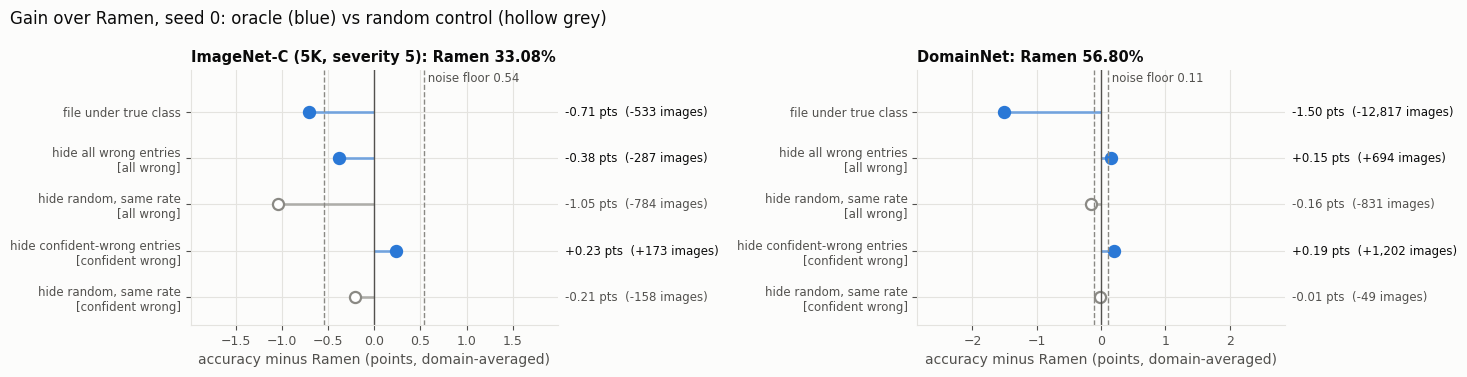

In [6]:
oa.plot_gains(exps);

**Per domain.** Where does hiding entries help or hurt? Rows = runs, columns = corruptions / domains, cells = points vs Ramen.

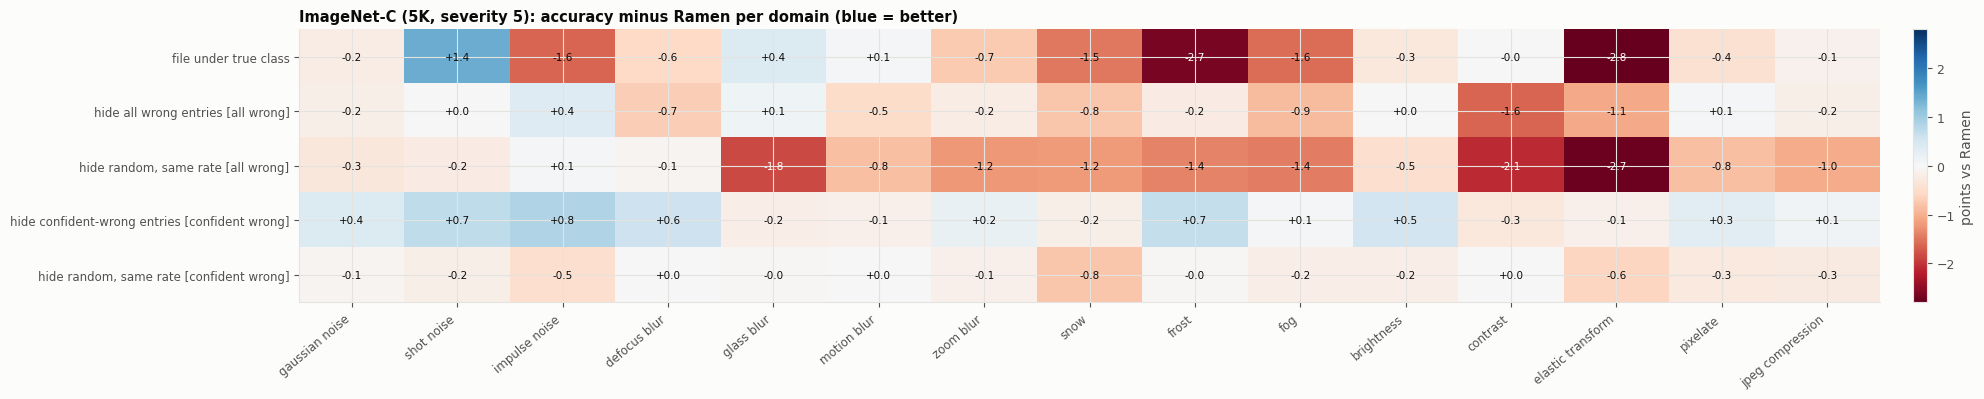

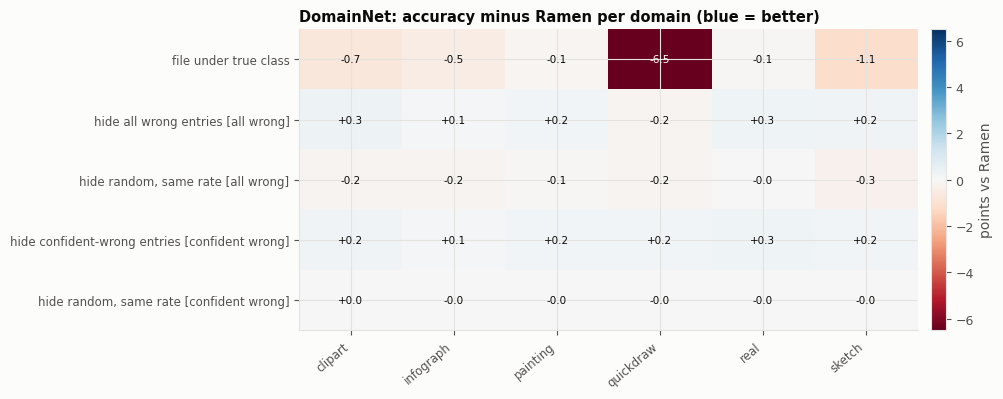

In [7]:
for ds, exp in exps.items():
    oa.plot_domain_gain(exp, ds)

## 4b. Seeds 1–4: is the confident-wrong gain repeatable?

The seed-0 screen found one variant above the noise floor: hiding confident-wrong entries on DomainNet (+0.19 points). Here it and its random control run on four more stream orders (seeds 1–4), on both datasets. *Aligned* = every run saw exactly the same stream as the cached Ramen run of that seed (same image at every position); if it is False, that seed's comparison is invalid.

In [8]:
seeds = {ds: oa.seed_table(ds) for ds in ['ImageNetC5K', 'DomainNet']}
for ds, t in seeds.items():
    print(oa.LABEL[ds])
    display(t.round(2))

ImageNet-C (5K, severity 5)


,Ramen %,hide confident-wrong entries %,oracle_drop_cw pts,oracle_drop_cw images,"hide random, same rate %",oracle_random_like_cw pts,oracle_random_like_cw images,oracle minus control (pts),aligned
seed,,,,,,,,,
0,33.08,33.31,0.23,173,32.87,-0.21,-158,0.44,True
1,33.17,33.31,0.14,106,32.78,-0.39,-296,0.54,True
2,33.02,33.32,0.30,227,32.79,-0.23,-169,0.53,True
3,32.91,33.21,0.31,229,32.77,-0.13,-101,0.44,True
4,32.96,33.20,0.24,177,32.74,-0.23,-169,0.46,True


DomainNet


,Ramen %,hide confident-wrong entries %,oracle_drop_cw pts,oracle_drop_cw images,"hide random, same rate %",oracle_random_like_cw pts,oracle_random_like_cw images,oracle minus control (pts),aligned
seed,,,,,,,,,
0,56.80,56.99,0.19,1202,56.79,-0.01,-49,0.20,True
1,56.79,56.96,0.17,1079,56.77,-0.02,-27,0.19,True
2,56.83,57.02,0.19,1174,56.81,-0.02,-93,0.21,True
3,56.81,56.95,0.14,955,56.75,-0.06,-288,0.20,True
4,56.85,56.99,0.14,922,56.81,-0.04,-152,0.18,True


**Summary over seeds.** Mean ± standard deviation of the change vs Ramen; a gain counts if the mean clears the noise floor and the oracle beats its control on every seed.

In [9]:
oa.seed_summary(seeds)

seeds vs Ramen, mean +- std (pts) vs Ramen, mean (images)          seeds above Ramen noise floor mean clears floor
ImageNet-C (5K, severity 5) hide confident-wrong entries         5               +0.24 +- 0.07                    +182                     5 of 5        0.54                no
                            hide random, same rate (control)     5               -0.24 +- 0.10                    -179                     0 of 5        0.54                no
                            oracle minus control                 5               +0.48 +- 0.05                          5 of 5 (oracle > control)                              
DomainNet                   hide confident-wrong entries         5               +0.17 +- 0.02                  +1,066                     5 of 5        0.11               yes
                            hide random, same rate (control)     5               -0.03 +- 0.02                    -122                     0 of 5        0.11                no
                            oracle minus control                 5               +0.20 +- 0.01                          5 of 5 (oracle > control)

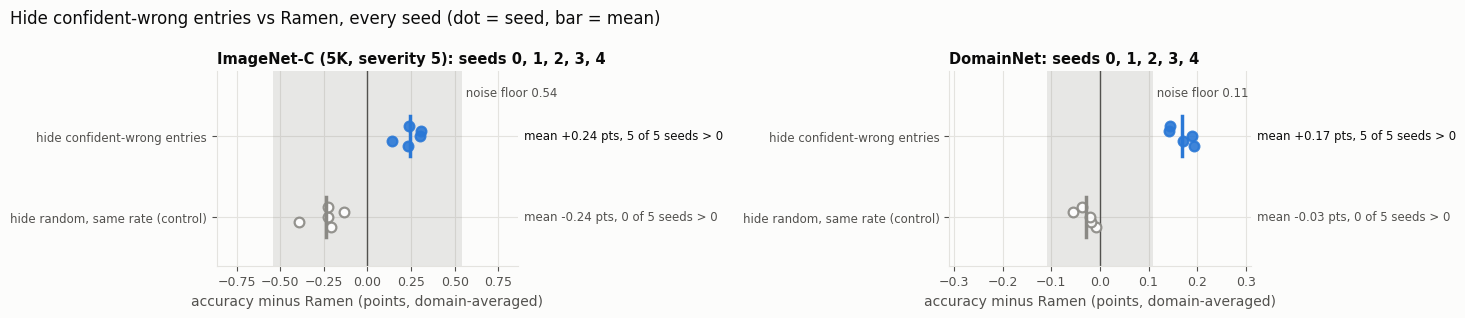

In [10]:
oa.plot_seeds(seeds);

## 5. Why: what the memory and the retrieved support contain

**Ramen's memory over the stream** (run `oracle_none`, which is Ramen): how many stored entries were filed from a correct zero-shot prediction, a wrong one, or a confidently wrong one. Counts, sampled every 10 batches.

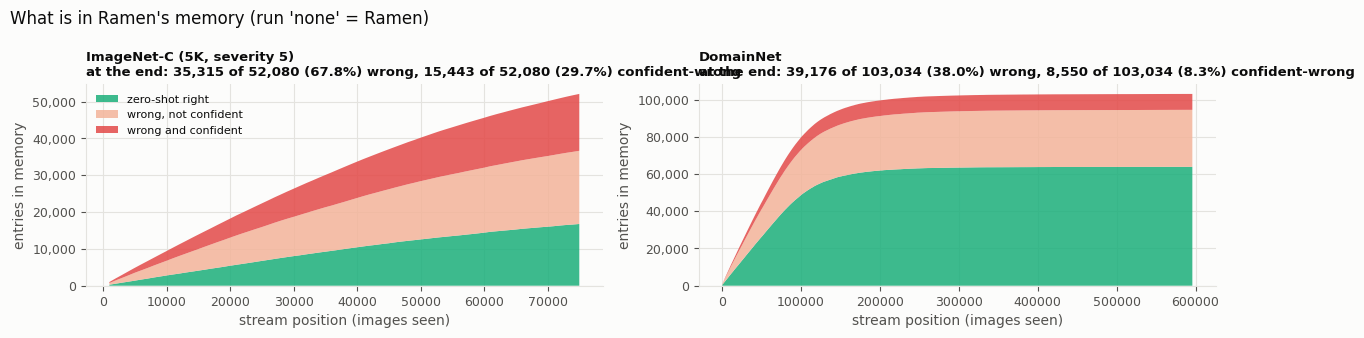

In [11]:
oa.plot_memory_composition(exps);

**Contamination of the retrieved support.** For each query, the share of its update weight that came from entries whose zero-shot prediction was wrong (rolling mean along the stream). The oracles should push this towards 0; the random controls should leave it near Ramen's level.

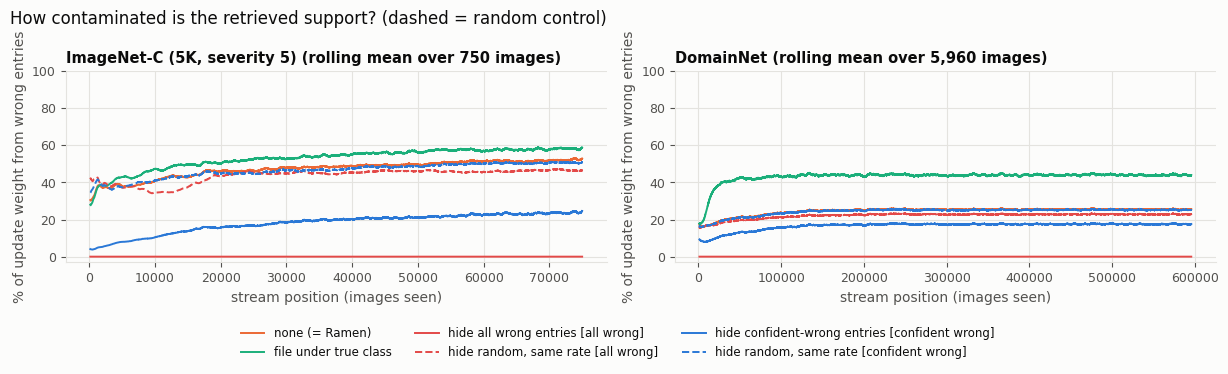

In [12]:
oa.plot_support_contamination(exps);

## 6. Interpretation

Domain-averaged accuracy, compared with Ramen on the same stream. All variants ran on seed 0; the confident-wrong oracle and its control also ran on seeds 1–4 (section 4b).

**The setup is sound.** `oracle_none` reproduces Ramen on 75,000 of 75,000 ImageNet-C images and 596,006 of 596,006 DomainNet images (100.0%).

**1. Hiding confident-wrong entries is the only variant that helps on both datasets, and it repeats on every seed.**
- DomainNet: **+0.17 ± 0.02 points over seeds 0–4 (about +1,066 images per seed)**, 5 of 5 seeds positive, every seed above the 0.11 floor (+0.14 to +0.19). Seed 0: +0.19, every one of the 6 domains gains (+0.13 to +0.26). Its random control: −0.03 ± 0.02, 0 of 5 seeds positive.
- ImageNet-C: **+0.24 ± 0.07 points (about +182 images per seed)**, 5 of 5 seeds positive, but below the 0.54 floor on every seed. Seed 0: 10 of 15 corruptions gain. Its random control: −0.24 ± 0.10.
- Oracle minus control: +0.20 ± 0.01 (DomainNet) and +0.48 ± 0.05 (ImageNet-C), positive on 5 of 5 seeds on both.
- It hides little: 8,550 of 103,034 memory entries on DomainNet (8.3%) and 15,443 of 52,080 on ImageNet-C (29.7%). It cuts the support weight from wrong entries from 24.5% to 16.6% (DomainNet) and from 47.3% to 18.2% (ImageNet-C).

**2. Contamination matters: every oracle beats its random control.** On seed 0, ImageNet-C margins are +0.67 points for hiding all wrong entries and +0.44 for hiding confident-wrong. On DomainNet they are +0.31 and +0.20. Hiding *which* entries matters, not just hiding fewer.

**3. Removing all contamination is not better than removing the confident part.**
- Hiding all wrong entries: +0.15 on DomainNet and −0.38 on ImageNet-C. It hides 68% of ImageNet-C's memory (35,315 of 52,080), so the support shrinks. Its random control loses even more (−1.05), which is the cost of a smaller support on its own.
- Filing every image under its true class (100% pure queues) hurts on both: −0.71 (ImageNet-C) and −1.50 (DomainNet; −6.49 on quickdraw). Pure queues are not the goal. This agrees with the earlier RamenClean result: purity never bought accuracy, support size matters.

**4. What this means for a method.** The opportunity is narrow: a *label-free* detector of confidently wrong entries, used to drop or down-weight them while keeping the rest of the support. Even the perfect oracle gains only about +0.17 (DomainNet) to +0.24 (ImageNet-C) points, so a real detector will capture part of that. On ImageNet-C even the oracle does not clear the noise floor.

**Caveats.** Only the confident-wrong oracle and its control have seeds 0–4; the other variants are seed 0 only. Oracles use the true labels and are upper bounds, not methods. The confident threshold (running median entropy) was not tuned. The fp16 priority saturation in Ramen's cache is kept on purpose so the variants match Ramen.

**Next step.**
- Test label-free signals for "confident but wrong" against the oracle's flags (AUROC). Candidates: disagreement with the kNN neighbourhood's labels, distance to the class prototype, and prediction flips under augmentation.
- A signal is worth building on only if hiding its flagged entries keeps most of the oracle's +0.17 on DomainNet.

## 7. Glossary

| Term | Meaning |
|---|---|
| Active set / support | The memory entries retrieved for one query and averaged into its update. |
| Broken | Zero-shot CLIP was right on the image, the run is wrong. |
| Class queue | Ramen's memory holds one fixed-size queue per class; each image is filed in the queue of its zero-shot predicted class. When a queue is full, the newest image replaces the oldest. |
| Confident wrong | An image zero-shot CLIP gets wrong with entropy below the running median of all images seen so far. Low entropy = confident; Ramen gives these the largest retrieval weight. |
| Contamination | Memory entries filed under a class that is not their true class (their zero-shot prediction was wrong). |
| Control (random) | A run that hides the same fraction of entries at random. It separates "hiding the wrong ones" from "hiding any". |
| Domain | One sub-population of the stream: a corruption type in ImageNet-C (e.g. gaussian noise), a style in DomainNet (clipart, quickdraw, …). |
| Domain-averaged accuracy | Mean of the per-domain accuracies (the paper's metric). Differs from pooled accuracy on DomainNet, whose domains have very different sizes. |
| Entropy (H) | Uncertainty of a prediction: −Σ p log p over the class probabilities. 0 = fully confident. |
| Entropy-minimisation gradient | The gradient that makes the model more confident in its current prediction. Ramen stores one per image and replays retrieved ones as the update. |
| Fixed | Zero-shot CLIP was wrong on the image, the run is right. |
| Hidden entry | An entry the oracle never retrieves. It stays in memory and still takes a slot. |
| Mixed stream | Test images from all domains shuffled into one stream. |
| NoAdapt / zero-shot | Frozen CLIP classifying by similarity to class-name prompts; no test-time updates. |
| Noise floor | 2 × (max − min) of Ramen's accuracy over seeds 0–4. A gain counts only if larger. |
| Oracle | A variant allowed to use the true labels. Not a usable method: an upper bound on what a perfect detector could achieve. |
| Purity | Share of memory entries filed under their true class. |
| Ramen | The test-time adaptation baseline: memory of past test images + one SignSGD step per batch on gradients retrieved from it, then the parameters are reset. |
| Seed | Fixes the stream order (and the controls' random draws). NoAdapt is identical across seeds. |
| SignSGD | Update that uses only the sign of each gradient component (step size 0.01 here). |
| Support weight | The share of a query's update contributed by an entry: exp(−H)·exp(−β·distance), normalised. |
